# Prepoznavanje zdravstvenog stanja pčela sa fotografije
### KORAK 3: Transfer learning i trening na VarroaDataset-u

Tri arhitekture — **MobileNetV3-Large, ResNet50, EfficientNetB0** — prethodno istrenirane na ImageNet-u
(1,28 miliona slika) prilagođavaju se zadatku *zdrava / varoa* pod **istim uslovima**.

Trening se pokreće iz terminala (`./run_varroa.sh`, oko 1,5 h na Apple M5); ovde se prikazuje postupak i
čitaju rezultati iz `runs/`.

**Šta je biblioteka, a šta naš kod:** arhitekture i ImageNet težine dolaze iz `torchvision` i nisu menjane.
Naš kod (`src/models.py`, `src/train.py`) menja poslednji sloj, bira šta se trenira, priprema slike i vodi trening.

## 1. Uvoz biblioteka

In [1]:
import sys, os, json, ast, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw

# src.evaluate pri importu prebacuje matplotlib u "Agg" (bez prikaza) — zato se
# učitava ovde, pa se prikaz u notebook-u vraća sa %matplotlib inline
import src.evaluate, src.model_checks
%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 60)

GRAFICI = ROOT / "grafici"; GRAFICI.mkdir(exist_ok=True)
RUNS = ROOT / "runs"

# Iste boje u svim graficima
BOJA_KLASE = {"zdrava": "#2ecc71", "varoa": "#e74c3c"}
BOJA_MODELA = {"MobileNetV3-Large": "#3498db", "ResNet50": "#9b59b6", "EfficientNetB0": "#f39c12"}
MODELI = ["MobileNetV3-Large", "ResNet50", "EfficientNetB0"]
RUN_ZA = {"MobileNetV3-Large": "varroa_mobilenet_v3_large", "ResNet50": "varroa_resnet50",
          "EfficientNetB0": "varroa_efficientnet_b0"}

def sacuvaj(ime):
    """Čuva trenutni grafik u grafici/<ime>.png (isti grafici idu u prezentaciju)."""
    plt.savefig(GRAFICI / f"{ime}.png", dpi=150, bbox_inches="tight")

def oznaci_stubice(ax, fmt="{:.3f}", rot=0, size=9):
    for p in ax.patches:
        h = p.get_height()
        if np.isfinite(h) and h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h), ha="center",
                        va="bottom", fontsize=size, rotation=rot, xytext=(0, 2), textcoords="offset points")

print("Biblioteke uspešno učitane. Koren projekta:", ROOT)

Biblioteke uspešno učitane. Koren projekta: /Users/medzidjasarovic/Kosnica_IS/KosnicaML


## 2. Transfer learning u tri poteza

1. učita se mreža istrenirana na ImageNet-u
2. poslednji sloj (1.000 klasa) zameni se novim sa **2 izlaza** — `zdrava`, `varoa`
3. **faza 1:** telo zamrznuto, trenira se samo nova glava (3 epohe, lr 10⁻³) →
   **faza 2:** odmrzne se **cela mreža** i trenira sa 10× manjom stopom učenja (15 epoha, lr 10⁻⁴)

In [2]:
from src.models import build_model, freeze_backbone, unfreeze_all, count_parameters, display_name
param = []
for arch in ["mobilenet_v3_large", "resnet50", "efficientnet_b0"]:
    model, _, _ = build_model(arch, 2, "letterbox")
    ukupno = count_parameters(model)[0]
    freeze_backbone(model, arch); faza1 = count_parameters(model)[1]
    param.append({"Model": display_name(arch), "ukupno parametara": ukupno, "trenira se u fazi 1": faza1, "u fazi 2": ukupno})
param = pd.DataFrame(param).set_index("Model"); param

,ukupno parametara,trenira se u fazi 1,u fazi 2
Model,,,
MobileNetV3-Large,4204594,1232642,4204594
ResNet50,23512130,4098,23512130
EfficientNetB0,4010110,2562,4010110


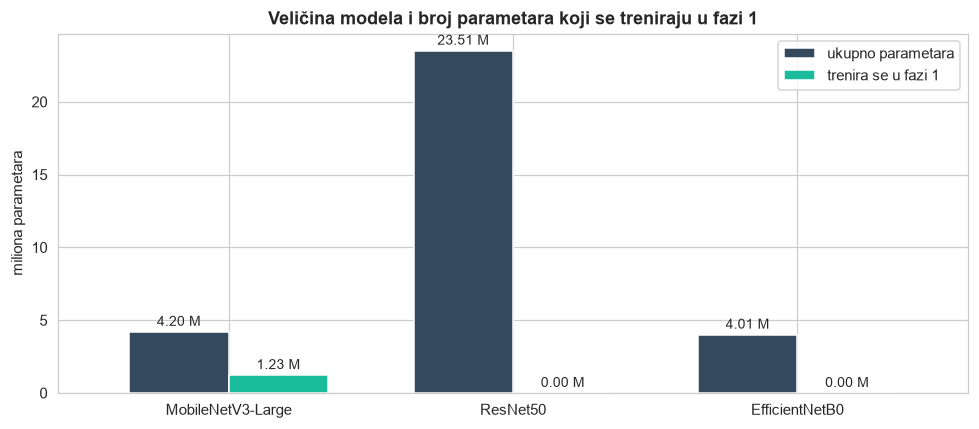

In [3]:
ax = (param[["ukupno parametara", "trenira se u fazi 1"]] / 1e6).plot(kind="bar", figsize=(9, 4), rot=0,
                                                                   color=["#34495e", "#1abc9c"], width=0.7)
oznaci_stubice(ax, "{:.2f} M"); ax.set_ylabel("miliona parametara"); ax.set_xlabel("")
ax.set_title("Veličina modela i broj parametara koji se treniraju u fazi 1")
plt.tight_layout(); sacuvaj("03a_parametri"); plt.show()

## 3. Priprema slike: zašto *letterbox*, a ne standardno isecanje

Standardna priprema (`weights.transforms()`) smanji kraću stranu na 232 px i iseče centralni kvadrat 224×224.
Slike u VarroaDataset-u su **uspravne (160×280)** — isecanje bi odbacilo glavu i zadak pčele, gde je grinja često.
**Letterbox** smanji celu sliku i dopuni je do kvadrata. Ista funkcija (`service/preprocessing.py`) radi i u servisu.

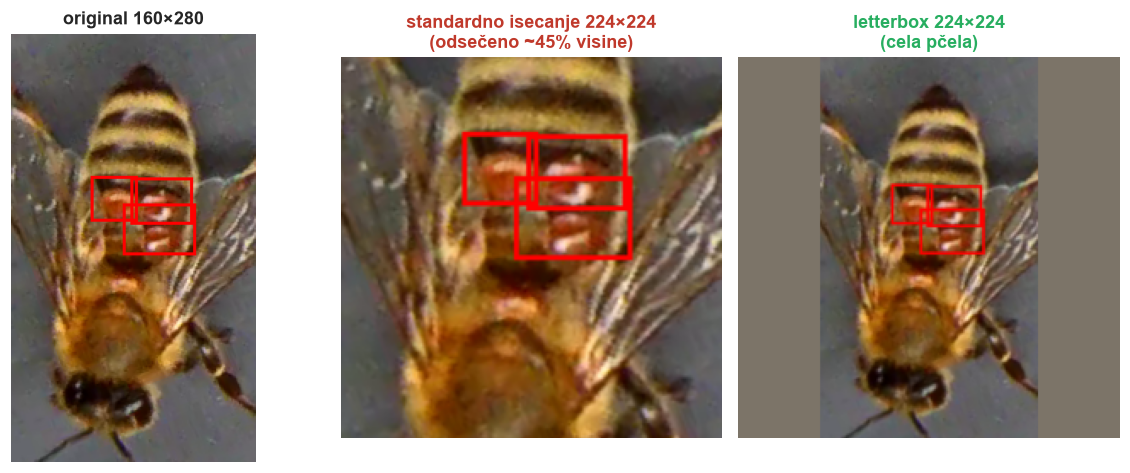

In [4]:
from src.varroa_dataset import parse_gt
from service.preprocessing import letterbox
gt = parse_gt()
row = gt[(gt["n_mites"] > 0) & (gt["split"] == "val")].iloc[5]
img = Image.open(row["path"]).convert("RGB"); d = ImageDraw.Draw(img)
for b in row["boxes"]: d.rectangle(b, outline=(255, 0, 0), width=2)
w, h = img.size; s = 232 / w; rs = img.resize((232, round(h * s)))
top = (rs.height - 224) // 2; centar = rs.crop((4, top, 228, top + 224))

fig, axes = plt.subplots(1, 3, figsize=(11, 4.4))
axes[0].imshow(img); axes[0].set_title("original 160×280")
axes[1].imshow(centar); axes[1].set_title("standardno isecanje 224×224\n(odsečeno ~45% visine)", color="#c0392b")
axes[2].imshow(letterbox(img, 224)); axes[2].set_title("letterbox 224×224\n(cela pčela)", color="#27ae60")
for a in axes: a.axis("off")
plt.tight_layout(); sacuvaj("03b_letterbox"); plt.show()

## 4. Augmentacija

Tokom treninga svaka slika se pri svakom prolazu nasumično menja: rotacija u svim smerovima (pčela je
snimljena odozgo), preslikavanje, pomeranje, promena razmere, osvetljenja, kontrasta, boje i blago
zamućenje. Nijansa se menja vrlo malo — crvenkasta boja grinje je signal.

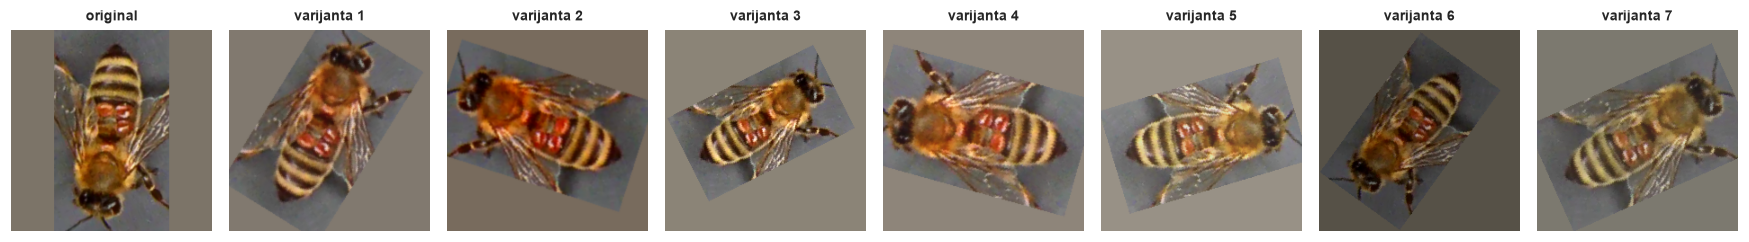

In [5]:
import torch
_, train_tf, eval_tf = build_model("mobilenet_v3_large", 2, "letterbox")
torch.manual_seed(0)
orig = Image.open(row["path"]).convert("RGB")
mean = torch.tensor(eval_tf.mean).view(3, 1, 1); std = torch.tensor(eval_tf.std).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for i, ax in enumerate(axes):
    x = eval_tf(orig) if i == 0 else train_tf(orig)
    ax.imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0)); ax.axis("off")
    ax.set_title("original" if i == 0 else f"varijanta {i}", fontsize=9)
plt.tight_layout(); sacuvaj("03c_augmentacija"); plt.show()

## 5. Izbor protokola treninga (samo na validacionom skupu)

Prvi pokušaj (**A**) koristio je protokol iz BeeImage eksperimenta: fine-tuning samo **poslednjeg bloka**.
Model nije naučio zadatak. Varijante su upoređene **isključivo na validacionom skupu** (drugi snimci),
na MobileNetV3 kao najbržoj mreži; izabrani protokol je zatim primenjen na sve tri arhitekture.
Test skup nije korišćen.

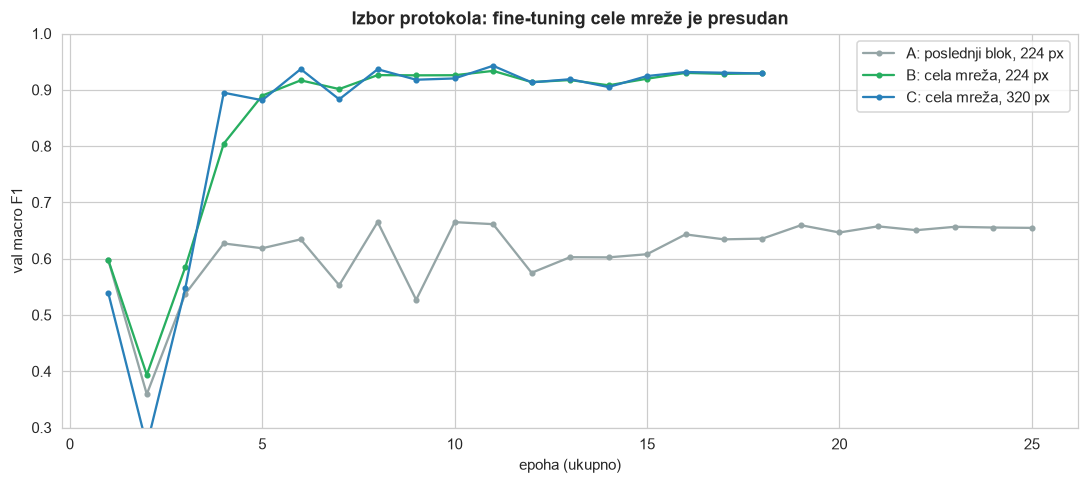

,train tačnost (kraj),najbolji val F1,trening (min)
varijanta,,,
"A: poslednji blok, 224 px",0.7590,0.6651,7.8
"B: cela mreža, 224 px",0.9274,0.9336,13.1
"C: cela mreža, 320 px",0.9346,0.9427,61.4


In [6]:
tun = []
fig, ax = plt.subplots(figsize=(10, 4.5))
boje = {"A": "#95a5a6", "B": "#27ae60", "C": "#2980b9"}
for d in sorted((RUNS / "tuning").iterdir()):
    c = json.loads((d / "config.json").read_text()); hst = pd.read_csv(d / "history.csv")
    k = d.name[0]
    opis = f"{k}: {'cela mreža' if c.get('finetune_scope') == 'all' else 'poslednji blok'}, {c.get('img_size', 224)} px"
    ax.plot(range(1, len(hst) + 1), hst["val_macro_f1"], marker="o", ms=3, label=opis, color=boje[k])
    tun.append({"varijanta": opis, "train tačnost (kraj)": hst["train_acc"].iloc[-1],
                "najbolji val F1": c["best_val_macro_f1"], "trening (min)": round(c["train_seconds"] / 60, 1)})
ax.set_xlabel("epoha (ukupno)"); ax.set_ylabel("val macro F1"); ax.set_ylim(0.3, 1)
ax.set_title("Izbor protokola: fine-tuning cele mreže je presudan"); ax.legend()
plt.tight_layout(); sacuvaj("03d_izbor_protokola"); plt.show()
pd.DataFrame(tun).set_index("varijanta").round(4)

**Zaključak:** kada se odmrzne cela mreža, validacioni F1 skače sa **0,665 na 0,934**. Zamrznuti
slojevi, naučeni na ImageNet-u, ne izdvajaju sitno obeležje kao što je grinja. Veća slika (C, 320 px)
daje još ~0,01 — manje od oscilacija između epoha — a 4,7× je sporija. **Izabrana je varijanta B.**

## 6. Krive učenja — sve tri arhitekture, isti protokol

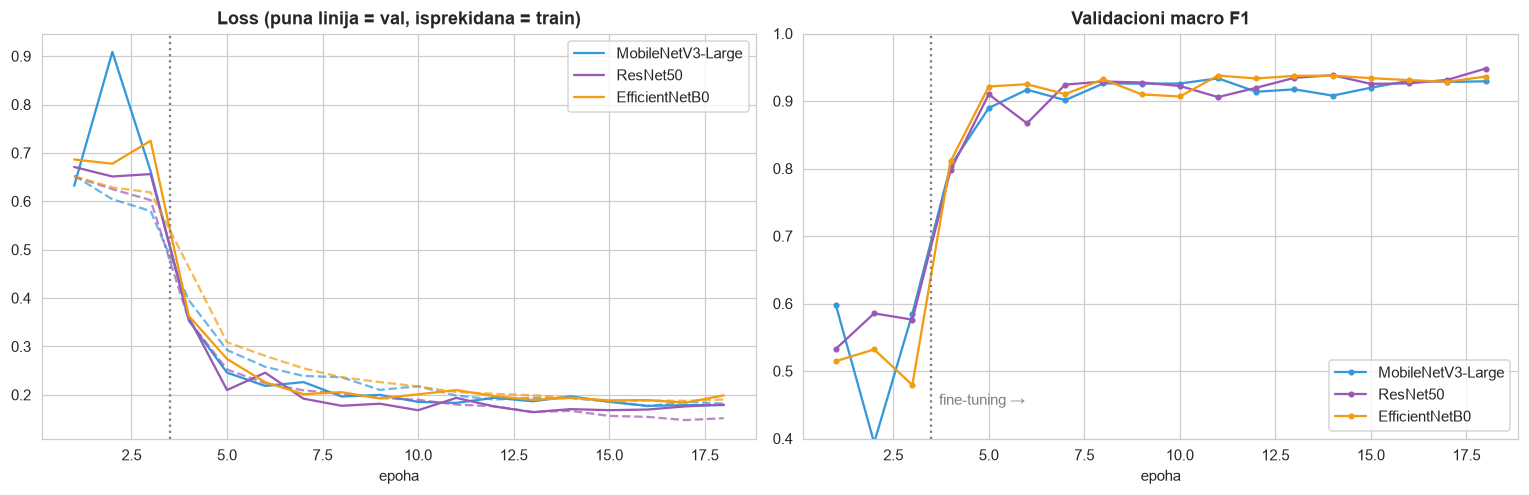

,najbolji val F1,epoha,trening (min)
MobileNetV3-Large,0.9336,finetune 8,20.4
ResNet50,0.948,finetune 15,40.0
EfficientNetB0,0.9377,finetune 8,24.8


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for m in MODELI:
    h = pd.read_csv(RUNS / RUN_ZA[m] / "history.csv"); x = range(1, len(h) + 1)
    axes[0].plot(x, h["train_loss"], color=BOJA_MODELA[m], ls="--", alpha=0.7)
    axes[0].plot(x, h["val_loss"], color=BOJA_MODELA[m], label=m)
    axes[1].plot(x, h["val_macro_f1"], color=BOJA_MODELA[m], marker="o", ms=3, label=m)
for a in axes:
    a.axvline(3.5, color="gray", ls=":"); a.set_xlabel("epoha"); a.legend()
axes[0].set_title("Loss (puna linija = val, isprekidana = train)"); axes[1].set_title("Validacioni macro F1")
axes[1].text(3.7, 0.45, "fine-tuning →", color="gray"); axes[1].set_ylim(0.4, 1)
plt.tight_layout(); sacuvaj("03e_krive_ucenja"); plt.show()
cfg = {m: json.loads((RUNS / RUN_ZA[m] / "config.json").read_text()) for m in MODELI}
pd.DataFrame({m: {"najbolji val F1": c["best_val_macro_f1"], "epoha": f"{c['best_stage']} {c['best_epoch']}",
                  "trening (min)": round(c["train_seconds"] / 60, 1)} for m, c in cfg.items()}).T

**Zaključak KORAKA 3:** sve tri mreže uče stabilno; val loss prati train loss (nema izraženog
preprilagođavanja). Najbolji checkpoint se bira po val macro F1 — test skup tek u KORAKU 4.